# Comprensión de los datos
**Caso Dinámica Inmobiliaria — Gerencia de Proyectos de Analytics (MIAD)**
Compraventas urbanas de Medellín (2021–2023) · Fuente: *Registro de Transacciones Inmobiliarias en Colombia IGAC* (Socrata `7y2j-43cv`)

Este notebook cubre **solo la fase de adquisición y entendimiento de datos**. El problema de negocio del caso (estimar el valor registrado e identificar operaciones atípicas) se resolverá en una etapa posterior; aquí se prepara el terreno para ello.

| Sección | Punto de la guía que resuelve |
|---|---|
| 1. Carga y trazabilidad | Identificación de la fuente |
| 2. Fuentes de información | Identificación y justificación de las fuentes |
| 3. Diccionario de variables | Descripción de las variables disponibles |
| 4. Calidad de datos | Calidad y limitaciones |
| 5. Transformaciones | Posibles transformaciones |
| 6. Recursos y necesidades de datos | Recursos tecnológicos y necesidades de datos |

In [1]:
import hashlib, platform, sys, re, difflib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 80)
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

# ---- Parámetros (ajustar la ruta si el CSV está en otra carpeta) ----
# RUTA_CSV = Path("C:/Users/oscar/OneDrive - Universidad de los Andes/Posgrado/03. Gerencia de proyectos Analytics/Registro_de_transacciones_inmobiliarias_en_Colombia_IGAC_20261023.csv")
# SALIDAS  = Path("salidas"); SALIDAS.mkdir(exist_ok=True)

In [2]:
import pandas as pd
from data_quality_checks import run_quality_checks, completeness_report,normalize_columns
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import hashlib, platform, sys, re, difflib
from pathlib import Path
import pandas as pd
import seaborn as sns


pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


In [74]:
# --------------------------------------------------
# 2. FILE CONFIGURATION
# --------------------------------------------------
## APUNTAR A LA CARPETA DONDE ESTÁ EL PARQUET
output_path = Path(
    r"C:\Users\oscar\OneDrive - Universidad de los Andes\Posgrado\03. Gerencia de proyectos Analytics\data"
)

RUTA_PARQUET = output_path / "dataset_batch_001.parquet"

SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)

# --------------------------------------------------
# 3. LOAD PARQUET FILE
# --------------------------------------------------

raw = pd.read_parquet(RUTA_PARQUET)


## Filtro de la poblacion 

In [75]:
raw = raw[raw['municipio'] == 'MEDELLÍN']

#raw = raw[raw['departamento'] == 'ANTIOQUIA']

In [76]:
raw["valor"] = pd.to_numeric(raw["valor"], errors="coerce")

# Standardize column names
raw.columns = raw.columns.str.upper().str.strip()

# Calculate SHA-256
sha256 = hashlib.sha256()

with open(RUTA_PARQUET, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

sha256 = sha256.hexdigest()

print(f"Archivo         : {RUTA_PARQUET.name}")
print(f"Tamaño          : {RUTA_PARQUET.stat().st_size / 1e6:,.1f} MB")
print(f"SHA-256         : {sha256}")
print(f"Filas x columnas: {raw.shape[0]:,} x {raw.shape[1]}")

# --------------------------------------------------
# 4. VERIFY EXTRACTION FILTERS
# --------------------------------------------------

filtros = {
    "MUNICIPIO = MEDELLÍN":
        raw["MUNICIPIO"].astype("string").str.strip() == "MEDELLÍN",

    "DIVIPOLA = 5001":
        raw["DIVIPOLA"].astype("string").str.strip() == "5001",

    "TIPO_PREDIO_ZONA = URBANO":
        raw["TIPO_PREDIO_ZONA"].astype("string").str.strip() == "URBANO",

    "COD_NATUJUR = 125":
        raw["COD_NATUJUR"].astype("string").str.strip() == "125",

    "NOMBRE_NATUJUR = COMPRAVENTA":
        raw["NOMBRE_NATUJUR"].astype("string").str.strip() == "COMPRAVENTA",

    "YEAR_RADICA en 2021-2023":
        raw["YEAR_RADICA"].astype("string").str.strip().isin(
            ["2021", "2022", "2023"]
        ),
    "VALOR > 0":
    pd.to_numeric(raw["VALOR"], errors="coerce") >= 0,

}

resultado_filtros = pd.DataFrame({
    "total_registros": {
        k: len(raw) for k in filtros
    },
    "cumplen": {
        k: int(v.sum()) for k, v in filtros.items()
    },
    "no_cumplen": {
        k: int((~v).sum()) for k, v in filtros.items()
    },
    "% del archivo": {
        k: v.mean() * 100 for k, v in filtros.items()
    }
})

display(resultado_filtros)

Archivo         : dataset_batch_001.parquet
Tamaño          : 207.5 MB
SHA-256         : dc7ff92caf14c5634548cb277770628a2ccf328a41136c207353b55092fa007c
Filas x columnas: 1,544,313 x 27


,total_registros,cumplen,no_cumplen,% del archivo
MUNICIPIO = MEDELLÍN,1544313,1544313,0,100.00
DIVIPOLA = 5001,1544313,1544313,0,100.00
TIPO_PREDIO_ZONA = URBANO,1544313,1536535,7778,99.50
COD_NATUJUR = 125,1544313,251784,1292529,16.30
NOMBRE_NATUJUR = COMPRAVENTA,1544313,251784,1292529,16.30
YEAR_RADICA en 2021-2023,1544313,682763,861550,44.21
VALOR > 0,1544313,240101,1304212,15.55


## 1. Carga y trazabilidad de la fuente
Se lee **todo como texto** (`dtype=str`) para no perder ceros a la izquierda (p. ej. `ORIP = 01N`), no interpretar mal los separadores de miles de `VALOR` y conservar el dato original intacto. Toda conversión se hace sobre una **copia** (sección 5).

In [77]:
sha256 = hashlib.sha256(RUTA_PARQUET.read_bytes()).hexdigest()


print(f"Archivo        : {RUTA_PARQUET.name}")
print(f"Tamaño         : {RUTA_PARQUET.stat().st_size/1e6:,.1f} MB")
print(f"SHA-256        : {sha256}")
print(f"Filas x columnas: {raw.shape[0]:,} x {raw.shape[1]}")

# Verificación de filtros de la extracción (según Guía 1)
filtros = {
    "MUNICIPIO = MEDELLÍN":        (raw["MUNICIPIO"] == "MEDELLÍN"),
    "DIVIPOLA = 5001":             (raw["DIVIPOLA"] == "5001"),
    "TIPO_PREDIO_ZONA = URBANO":   (raw["TIPO_PREDIO_ZONA"] == "URBANO"),
    "COD_NATUJUR = 125":           (raw["COD_NATUJUR"] == "125"),
    "NOMBRE_NATUJUR = COMPRAVENTA":(raw["NOMBRE_NATUJUR"] == "COMPRAVENTA"),
    "YEAR_RADICA en 2021-2023":    raw["YEAR_RADICA"].isin(["2021", "2022", "2023"]),
}
pd.DataFrame({"cumplen": {k: int(v.sum()) for k, v in filtros.items()},
              "% del archivo": {k: v.mean()*100 for k, v in filtros.items()}})

Archivo        : dataset_batch_001.parquet
Tamaño         : 207.5 MB
SHA-256        : dc7ff92caf14c5634548cb277770628a2ccf328a41136c207353b55092fa007c
Filas x columnas: 1,544,313 x 27


,cumplen,% del archivo
MUNICIPIO = MEDELLÍN,1544313,100.00
DIVIPOLA = 5001,1544313,100.00
TIPO_PREDIO_ZONA = URBANO,1536535,99.50
COD_NATUJUR = 125,251784,16.30
NOMBRE_NATUJUR = COMPRAVENTA,251784,16.30
YEAR_RADICA en 2021-2023,682763,44.21


In [78]:
raw.head(5).T

,0,1,2,3,4
PK,05001-001-000013-00014-00313-2018,05001-001-000014-00015-00313-2018,05001-001-000023-00007-00109-2020,05001-001-000065-00013-00317-2015,05001-001-000067-00014-00109-2016
MATRICULA,001-13,001-14,001-23,001-65,001-67
FECHA_RADICA_TEXTO,2018-02-05 00:00:00,2018-02-05 00:00:00,2020-12-02 00:00:00,2015-12-16 00:00:00,2016-03-29 00:00:00
FECHA_APERTURA_TEXTO,1973-01-11 00:00:00,1973-01-11 00:00:00,1973-01-10 00:00:00,1973-01-10 00:00:00,1973-01-11 00:00:00
YEAR_RADICA,2018,2018,2020,2015,2016
ORIP,1,1,1,1,1
DIVIPOLA,5001,5001,5001,5001,5001
DEPARTAMENTO,ANTIOQUIA,ANTIOQUIA,ANTIOQUIA,ANTIOQUIA,ANTIOQUIA
MUNICIPIO,MEDELLÍN,MEDELLÍN,MEDELLÍN,MEDELLÍN,MEDELLÍN
TIPO_PREDIO_ZONA,URBANO,URBANO,URBANO,URBANO,URBANO


## 2. Identificación y justificación de las fuentes de información

**Fuente principal.** *Registro de Transacciones Inmobiliarias en Colombia IGAC 2015–2023* (Socrata `7y2j-43cv`, datos.gov.co). Lo publica el IGAC a partir de información de transacciones de la **Superintendencia de Notariado y Registro (SNR)**, y es la fuente base indicada en el Caso. Se eligió porque:

- **Es la única fuente del caso con valor registrado por operación**, que es la variable que el problema futuro quiere estimar y contextualizar.
- **Cobertura temporal y territorial:** nacional, 2015–2023, con detalle departamental y municipal, lo que permite escoger y justificar un territorio.
- **Trazabilidad:** es un conjunto oficial y abierto, con identificador único; la extracción se puede reproducir con filtros exactos.
- Es una fuente **administrativa registral**: cada fila es un acto jurídico, no necesariamente una venta de mercado independiente.

**Recorte de este proyecto.** Medellín · zona urbana · naturaleza jurídica `125 – COMPRAVENTA` · radicaciones 2021–2023. Se justifica por volumen suficiente para análisis estadístico, ámbito municipal acotado y comparabilidad (una sola ciudad, un solo tipo de acto). Las limitaciones de representatividad se tratan en la sección 4.

**Fuentes complementarias (para la etapa futura, no se usan ahora).** El Caso indica que la selección debe guiarse por la pregunta y no por la disponibilidad:

| Fuente complementaria | Para qué serviría en el problema futuro | Estado |
|---|---|---|
| Información catastral (IGAC) | Área, uso, avalúo, ubicación del predio: hoy `NUMERO_CATASTRAL` viene 100 % vacío, así que no hay llave de enlace | Por evaluar: llave, cobertura y fecha |
| División político-administrativa / DIVIPOLA (DANE) | Códigos territoriales y posible desagregación (comuna, barrio) | Disponible, pero el CSV solo trae el municipio |
| Población y demografía (DANE) | Contexto de demanda por territorio | Útil solo si hay desagregación intramunicipal |
| Variables macroeconómicas (tasas de interés, inflación, IPVN, salario mínimo) | Comparar valores nominales entre 2021 y 2023 | Útil para ajuste monetario; requiere regla explícita |
| Actividad de construcción / licencias | Dinámica de oferta | Opcional |
| Ordenamiento territorial (POT) | Uso del suelo y zonificación | Opcional, requiere georreferenciación |
| Información registral o de riesgo pública | Contextualizar señales atípicas | Solo si su acceso y nivel de agregación son adecuados |

> Cada fuente adicional debe documentar: acceso, llave de enlace, cobertura histórica y regla de transformación, antes de incorporarse.

## 3. Descripción de las variables disponibles
Se combina un **perfil automático** (tipo, completitud, cardinalidad, ejemplo) con una **descripción funcional**. Las descripciones marcadas *provisional* son interpretaciones a confirmar contra el diccionario oficial de la fuente.

In [79]:
descripcion = {
 "PK":                      ("Identificador", "Llave del registro: DIVIPOLA-ORIP-matrícula-anotación-naturaleza jurídica-año.", "Confirmada por inspección"),
 "MATRICULA":               ("Identificador", "Matrícula inmobiliaria (folio) = ORIP + número. Un folio puede aparecer en varias filas.", "Provisional"),
 "FECHA_RADICA_TEXTO":      ("Temporal", "Fecha de radicación del acto en la ORIP (texto). No es la fecha de la escritura.", "Provisional"),
 "FECHA_APERTURA_TEXTO":    ("Temporal", "Fecha de apertura del folio de matrícula. No es la antigüedad de la construcción.", "Provisional"),
 "YEAR_RADICA":             ("Temporal", "Año de radicación. Variable de filtro (2021–2023).", "Confirmada"),
 "ORIP":                    ("Territorial/registral", "Oficina de Registro de Instrumentos Públicos: '1' (Medellín Sur) y '01N' (Medellín Norte).", "Provisional"),
 "DIVIPOLA":                ("Territorial", "Código DANE del municipio (5001 = Medellín). Constante en la extracción.", "Confirmada"),
 "DEPARTAMENTO":            ("Territorial", "Departamento. Constante (ANTIOQUIA).", "Confirmada"),
 "MUNICIPIO":               ("Territorial", "Municipio. Constante (MEDELLÍN).", "Confirmada"),
 "TIPO_PREDIO_ZONA":        ("Territorial", "Zona del predio (URBANO/RURAL). Constante (URBANO).", "Confirmada"),
 "CATEGORIA_RURALIDAD":     ("Territorial", "Categoría de ruralidad DANE. Constante ('Ciudades y aglomeraciones').", "Confirmada"),
 "NUM_ANOTACION":           ("Registral", "Número de la anotación dentro del folio; refleja cuántos actos tiene ese folio.", "Provisional"),
 "ESTADO_FOLIO":            ("Registral", "Estado del folio. Viene vacío en toda la extracción.", "Confirmada (vacía)"),
 "FOLIOS_DERIVADOS":        ("Registral", "Folios derivados del folio matriz. Vacío en toda la extracción.", "Confirmada (vacía)"),
 "Dinámica_Inmobiliaria":   ("Indicador", "Marca que el acto cuenta como dinámica inmobiliaria (=1). Constante.", "Provisional"),
 "COD_NATUJUR":             ("Jurídico", "Código de naturaleza jurídica (125 = compraventa). Constante.", "Confirmada"),
 "NOMBRE_NATUJUR":          ("Jurídico", "Nombre de la naturaleza jurídica. Constante (COMPRAVENTA).", "Confirmada"),
 "NUMERO_CATASTRAL":        ("Catastral", "Número predial nuevo. Vacío: no hay enlace catastral.", "Confirmada (vacía)"),
 "NUMERO_CATASTRAL_ANTIGUO":("Catastral", "Número predial antiguo. Vacío.", "Confirmada (vacía)"),
 "DOCUMENTO_JUSTIFICATIVO": ("Jurídico", "Texto libre: tipo, número y fecha del documento + notaría. Ej.: '01-ESCRITURA 722 DE 04-05-2023; NOTARIA TREINTA Y UNA DE MEDELLIN'. Base para agrupar filas de una misma escritura.", "Confirmada por inspección"),
 "COUNT_A":                 ("Transaccional", "Conteo de intervinientes 'A' (probablemente quien adquiere) en el acto.", "Provisional — validar"),
 "COUNT_DE":                ("Transaccional", "Conteo de intervinientes 'DE' (probablemente quien transfiere) en el acto.", "Provisional — validar"),
 "PREDIOS_NUEVOS":          ("Transaccional", "Indicador de predios nuevos asociados al acto (0/1).", "Provisional — validar"),
 "TIENE_VALOR":             ("Monetaria", "1 si el registro trae valor. Derivada de VALOR: no es predictor admisible.", "Confirmada"),
 "TIENE_MAS_DE_UN_VALOR":   ("Monetaria", "1 si el acto reporta más de un valor (solo 4 casos).", "Provisional"),
 "VALOR":                   ("Monetaria", "Valor registrado del acto en COP nominales, con comas de miles. Es la variable de interés futura. No es avalúo ni valor comercial.", "Confirmada"),
}
dic = []
for c in raw.columns:
    s = raw[c]
    nn = s.notna().sum()
    ej = s.dropna().iloc[0] if nn else ""
    rol, desc, estado = descripcion.get(c, ("?", "", ""))
    nun = s.nunique(dropna=True)
    uso = ("Vacía" if nn == 0 else "Constante" if nun == 1 else "Variable")
    dic.append({"variable": c, "rol": rol, "tipo_original": "texto", "no_nulos": nn,
                "% completitud": nn/len(s)*100, "únicos": nun, "comportamiento": uso,
                "ejemplo": str(ej)[:45], "descripción": desc, "estado": estado})
diccionario = pd.DataFrame(dic)
diccionario.to_csv(SALIDAS/"diccionario_variables.csv", index=False, encoding="utf-8-sig")
diccionario[["variable","rol","% completitud","únicos","comportamiento","ejemplo"]]

,variable,rol,% completitud,únicos,comportamiento,ejemplo
0,PK,Identificador,100.00,1544313,Variable,05001-001-000013-00014-00313-2018
1,MATRICULA,Identificador,100.00,564314,Variable,001-13
2,FECHA_RADICA_TEXTO,Temporal,100.00,1850,Variable,2018-02-05 00:00:00
3,FECHA_APERTURA_TEXTO,Temporal,100.00,13118,Variable,1973-01-11 00:00:00
4,YEAR_RADICA,Temporal,100.00,9,Variable,2018
5,ORIP,Territorial/registral,100.00,2,Variable,1
6,DIVIPOLA,Territorial,100.00,1,Constante,5001
7,DEPARTAMENTO,Territorial,100.00,1,Constante,ANTIOQUIA
8,MUNICIPIO,Territorial,100.00,1,Constante,MEDELLÍN
9,TIPO_PREDIO_ZONA,Territorial,100.00,3,Variable,URBANO


In [80]:
# Resumen: cuántas variables aportan información real
print(diccionario["comportamiento"].value_counts().to_string())
print("\nVariables vacías    :", diccionario.loc[diccionario.comportamiento=="Vacía","variable"].tolist())
print("Variables constantes:", diccionario.loc[diccionario.comportamiento=="Constante","variable"].tolist())
print("Variables con variación:", diccionario.loc[diccionario.comportamiento=="Variable","variable"].tolist())

comportamiento
Variable     19
Constante     6
Vacía         2

Variables vacías    : ['ESTADO_FOLIO', 'FOLIOS_DERIVADOS']
Variables constantes: ['DIVIPOLA', 'DEPARTAMENTO', 'MUNICIPIO', 'CATEGORIA_RURALIDAD_2024', ':CREATED_AT', ':UPDATED_AT']
Variables con variación: ['PK', 'MATRICULA', 'FECHA_RADICA_TEXTO', 'FECHA_APERTURA_TEXTO', 'YEAR_RADICA', 'ORIP', 'TIPO_PREDIO_ZONA', 'NUM_ANOTACION', 'DINAMICA_2024', 'COD_NATUJUR', 'NOMBRE_NATUJUR', 'DOCUMENTO_JUSTIFICATIVO', 'COUNT_A', 'COUNT_DE', 'PREDIOS_NUEVOS', 'TIENE_VALOR', 'TIENE_MAS_DE_UN_VALOR', ':ID', 'VALOR']


**Lectura.** De 26 columnas, la mayoría son constantes (consecuencia de los filtros) o están vacías (`ESTADO_FOLIO`, `FOLIOS_DERIVADOS`, `NUMERO_CATASTRAL*`). La información analítica real está en **tiempo, registro/folio, documento justificativo, conteos de intervinientes y VALOR**. No hay área, uso, estrato, antigüedad ni coordenadas: esto limita lo que se podrá estimar más adelante (ver secciones 4 y 6).

## 4. Calidad de los datos y limitaciones
Dimensiones del Caso: **completitud, unicidad, validez, consistencia, cobertura temporal/geográfica y valores atípicos**. No se imputa ni se elimina nada en este diagnóstico.

### 4.1 Preparación mínima para medir (copia, el original no se toca)

In [81]:
df = raw.copy()

# VALOR: quitar comas de miles, mantener punto decimal; vacíos y ceros se cuentan por separado
df["VALOR_NUM"] = pd.to_numeric(df["VALOR"], errors="coerce")
for c in ["YEAR_RADICA", "NUM_ANOTACION", "COUNT_A", "COUNT_DE", "PREDIOS_NUEVOS",
          "TIENE_VALOR", "TIENE_MAS_DE_UN_VALOR"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
df["F_RADICA"]   = pd.to_datetime(df["FECHA_RADICA_TEXTO"],  errors="coerce")
df["F_APERTURA"] = pd.to_datetime(df["FECHA_APERTURA_TEXTO"], errors="coerce")

# Parseo del documento justificativo: '01-ESCRITURA 722 DE 04-05-2023; NOTARIA X DE MEDELLIN'
pat = r"^(?P<cod_doc>\d+)-(?P<tipo_doc>\w+)\s+(?P<num_doc>\S+)\s+DE\s+(?P<f_doc>\d{2}-\d{2}-\d{4});\s*(?P<oficina>.*)$"
doc = df["DOCUMENTO_JUSTIFICATIVO"].str.extract(pat)
df = pd.concat([df, doc], axis=1)
df["F_DOC"] = pd.to_datetime(df["f_doc"], format="%d-%m-%Y", errors="coerce")
print("Documentos que no cumplen el patrón:", doc["tipo_doc"].isna().sum())

Documentos que no cumplen el patrón: 4684


### 4.2 Completitud por campo y por año

In [82]:
"NUMERO_CATASTRAL","NUMERO_CATASTRAL_ANTIGUO"

('NUMERO_CATASTRAL', 'NUMERO_CATASTRAL_ANTIGUO')

In [83]:
vars_clave = ["MATRICULA","FECHA_RADICA_TEXTO","FECHA_APERTURA_TEXTO","NUM_ANOTACION","DOCUMENTO_JUSTIFICATIVO",
              "COUNT_A","COUNT_DE","PREDIOS_NUEVOS","ESTADO_FOLIO","FOLIOS_DERIVADOS","VALOR", "TIENE_VALOR"]
comp_anio = (raw.groupby("YEAR_RADICA")[vars_clave].agg(lambda s: s.notna().mean()*100).T)
comp_anio["Total"] = raw[vars_clave].notna().mean()*100
comp_anio.to_csv(SALIDAS/"completitud_por_campo_y_anio.csv", encoding="utf-8-sig")

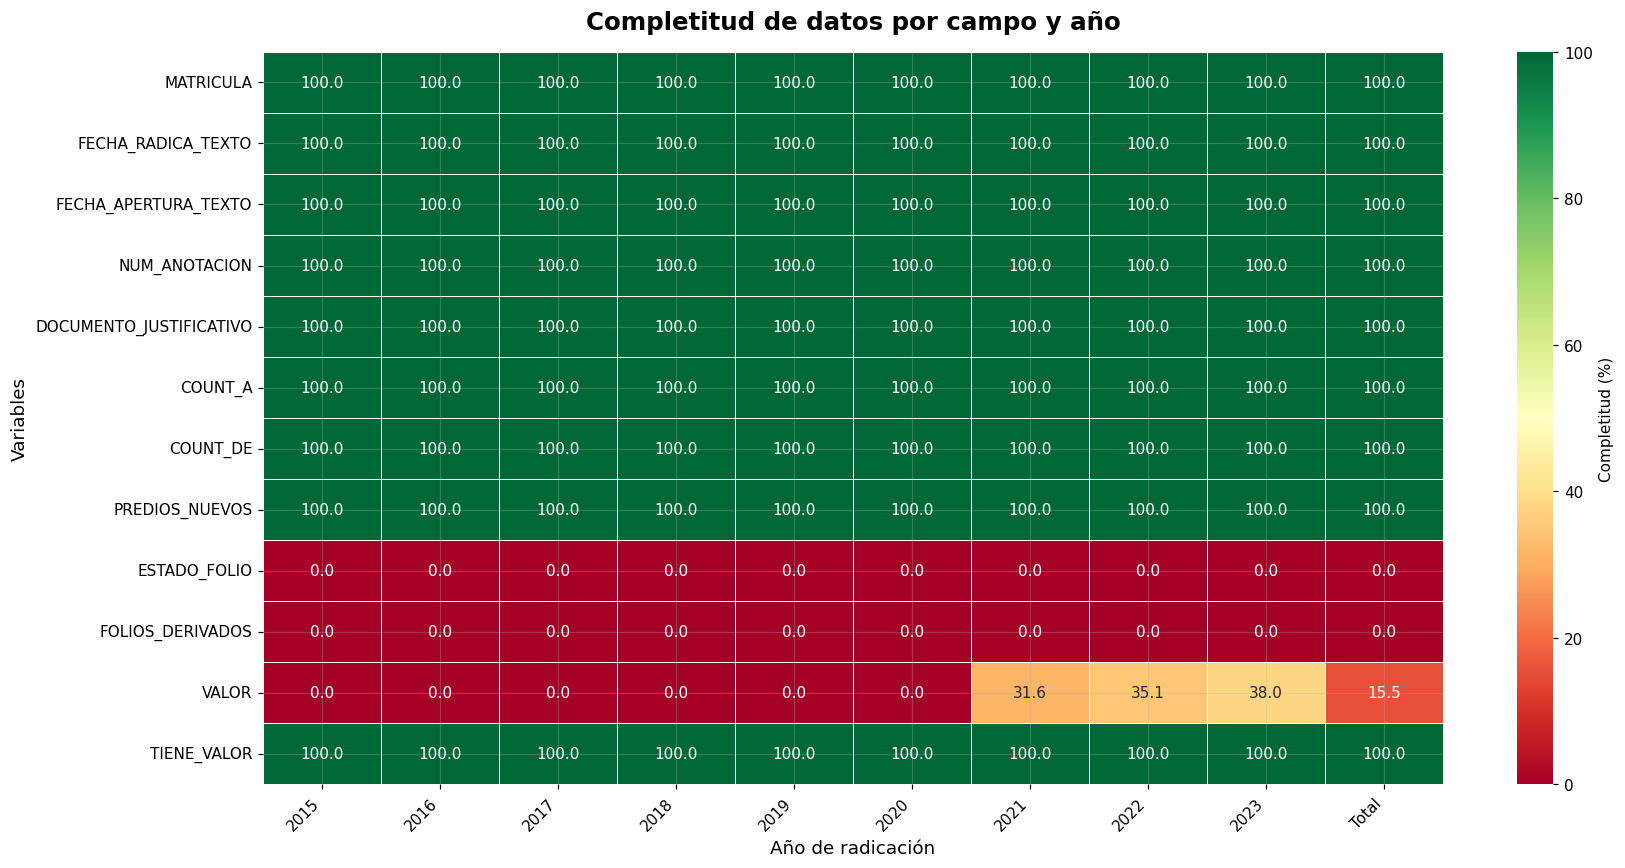

In [84]:
plt.figure(figsize=(16, 8))
sns.heatmap(
    comp_anio,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Completitud (%)"
    }
)

plt.title(
    "Completitud de datos por campo y año",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Año de radicación", fontsize=12)
plt.ylabel("Variables", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

In [85]:
# Cobertura monetaria 
cob = (df.assign(con_valor=df["VALOR_NUM"] >= 0)
         .groupby("YEAR_RADICA")
         .agg(elegibles=("PK","size"), con_valor=("con_valor","sum")))
cob.loc["Total"] = cob.sum()
cob["sin_valor"] = cob["elegibles"] - cob["con_valor"]
cob["cobertura_%"] = cob["con_valor"] / cob["elegibles"] * 100
print("Valores = 0:", int((df["VALOR_NUM"] == 0).sum()), "| Vacíos:", int(df["VALOR_NUM"].isna().sum()))
cob

Valores = 0: 2116 | Vacíos: 1304212


,elegibles,con_valor,sin_valor,cobertura_%
YEAR_RADICA,,,,
2015,198158,0,198158,0.00
2016,223820,0,223820,0.00
2017,141841,0,141841,0.00
2018,101993,0,101993,0.00
2019,74973,0,74973,0.00
2020,120765,0,120765,0.00
2021,176776,55900,120876,31.62
2022,282068,99005,183063,35.10
2023,223919,85196,138723,38.05


C:\Users\oscar\AppData\Local\Temp\ipykernel_21280\1744059991.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


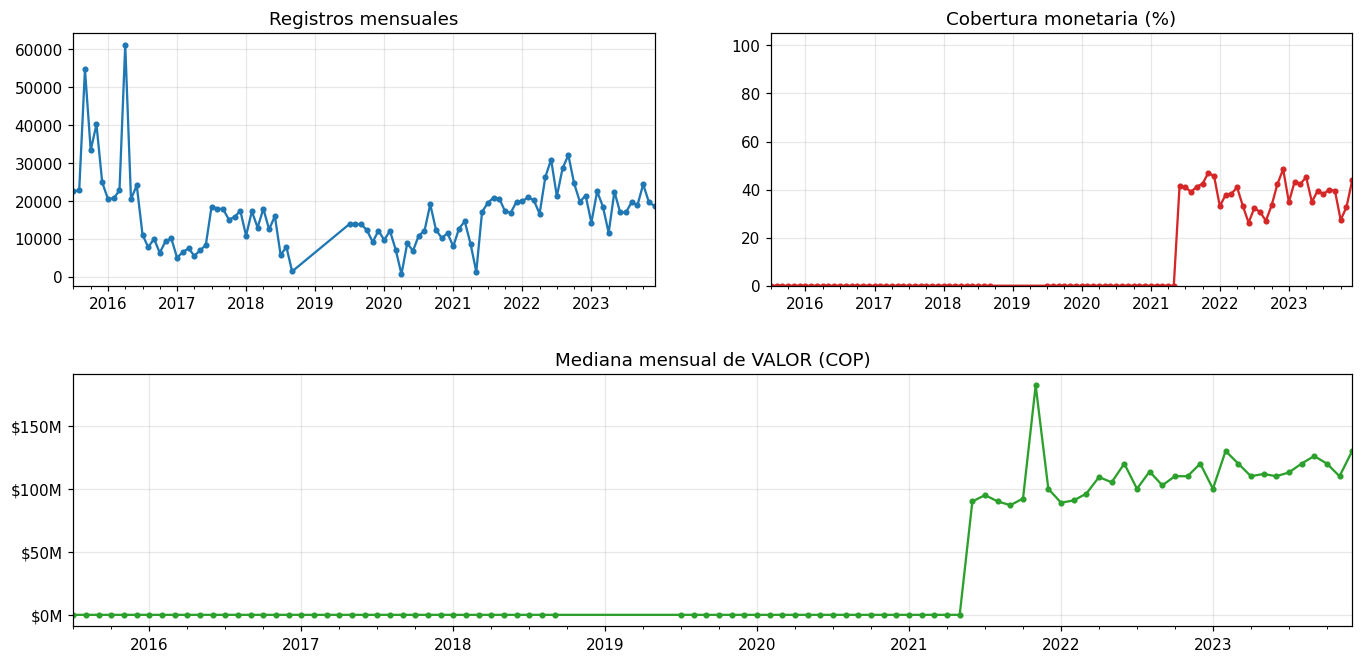

,registros,con_valor,mediana_valor,cobertura_%
MES_RADICA,,,,
2015-07,22498,0,0.00,0.00
2015-08,22703,0,0.00,0.00
2015-09,54648,0,0.00,0.00
2015-10,33354,0,0.00,0.00
2015-11,40118,0,0.00,0.00
...,...,...,...,...
2023-08,19629,7854,"120,000,000.00",40.01
2023-09,18813,7432,"126,000,000.00",39.50
2023-10,24339,6659,"120,000,000.00",27.36


In [86]:

# Cobertura monetaria y mediana mensual
df["MES_RADICA"] = df["F_RADICA"].dt.to_period("M")

mensual = df.groupby("MES_RADICA").agg(
    registros=("PK", "size"),
    con_valor=("VALOR_NUM", lambda s: (s > 0).sum()),
    mediana_valor=("VALOR_NUM", lambda s: s[s > 0].median() if (s > 0).any() else 0)
)

mensual["cobertura_%"] = mensual["con_valor"] / mensual["registros"] * 100

# Visualización: dos gráficos superiores y uno inferior
fig = plt.figure(figsize=(15, 7))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

mensual["registros"].plot(ax=ax1, marker="o", ms=3)
ax1.set_title("Registros mensuales")

mensual["cobertura_%"].plot(ax=ax2, marker="o", ms=3, color="tab:red")
ax2.set_title("Cobertura monetaria (%)")
ax2.set_ylim(0, 105)

mensual["mediana_valor"].plot(ax=ax3, marker="o", ms=3, color="tab:green")
ax3.set_title("Mediana mensual de VALOR (COP)")
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1e6:,.0f}M"))

for a in [ax1, ax2, ax3]:
    a.set_xlabel("")
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Meses con cobertura inferior al 95%
display(mensual[mensual["cobertura_%"] < 95].round(2))


In [87]:
resumen_anual = (
    df.groupby("YEAR_RADICA")
    .agg(
        cantidad_registros=("YEAR_RADICA", "size"),
        valores_validos=("VALOR_NUM", "count"),
        suma_valores=("VALOR_NUM", "sum"),
        promedio_valor=("VALOR_NUM", "mean"),
        mediana_valor=("VALOR_NUM", "median")
    )
    .reset_index()
)

display(resumen_anual)

,YEAR_RADICA,cantidad_registros,valores_validos,suma_valores,promedio_valor,mediana_valor
0,2015,198158,0,0.00,NaN,NaN
1,2016,223820,0,0.00,NaN,NaN
2,2017,141841,0,0.00,NaN,NaN
3,2018,101993,0,0.00,NaN,NaN
4,2019,74973,0,0.00,NaN,NaN
5,2020,120765,0,0.00,NaN,NaN
6,2021,176776,55900,"14,372,385,419,605.00","257,108,862.60","100,000,000.00"
7,2022,282068,99005,"28,314,893,630,956.00","285,994,582.40","100,000,000.00"
8,2023,223919,85196,"28,486,998,113,968.48","334,370,136.09","119,967,000.00"


### 4.3 Unicidad y unidad de observación

In [88]:
v = df[df["VALOR_NUM"] > 0]
unicidad = pd.Series({
    "Registros totales": len(df),
    "PK distintas (todo el archivo)": df["PK"].nunique(),
    "Registros con valor positivo": len(v),
    "PK distintas (con valor)": v["PK"].nunique(),
    "Matrículas distintas (con valor)": v["MATRICULA"].nunique(),
    "Documentos justificativos distintos (con valor)": v["DOCUMENTO_JUSTIFICATIVO"].nunique(),
})
print(unicidad.map("{:,}".format).to_string())
print(f"\nUnicidad de PK = {df['PK'].nunique()/len(df)*100:.2f} %")

Registros totales                                  1,544,313
PK distintas (todo el archivo)                     1,544,313
Registros con valor positivo                         237,985
PK distintas (con valor)                             237,985
Matrículas distintas (con valor)                     174,804
Documentos justificativos distintos (con valor)      123,748

Unicidad de PK = 100.00 %


Documentos con 1 sola fila      : 72,833
Documentos con 2 o más filas    : 50,915
   · de ellos, mismo valor en todas las filas: 29,113 (57.2 %)
Máximo de filas en un documento : 1648


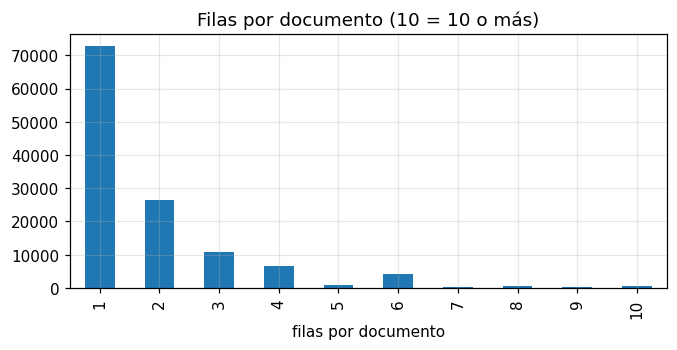

In [89]:
# ¿Una escritura aparece en varias filas? ¿repite el mismo valor?
g = v.groupby("DOCUMENTO_JUSTIFICATIVO").agg(filas=("PK","size"), matriculas=("MATRICULA","nunique"),
                                              valores_distintos=("VALOR_NUM","nunique"))
multi = g[g["filas"] > 1]
print(f"Documentos con 1 sola fila      : {(g.filas==1).sum():,}")
print(f"Documentos con 2 o más filas    : {len(multi):,}")
print(f"   · de ellos, mismo valor en todas las filas: {(multi.valores_distintos==1).sum():,} "
      f"({(multi.valores_distintos==1).mean()*100:.1f} %)")
print(f"Máximo de filas en un documento : {g.filas.max()}")
g["filas"].clip(upper=10).value_counts().sort_index().plot.bar(figsize=(7,3), title="Filas por documento (10 = 10 o más)")
plt.xlabel("filas por documento"); plt.show()

**Hallazgo clave para la unidad de observación.** Una misma escritura aparece en varias filas (varias matrículas/anotaciones) y, cuando eso ocurre, casi siempre **repite el mismo VALOR**: el valor parece ser del *documento*, no de cada inmueble. Por tanto, **la PK única no implica ventas independientes**; sumar `VALOR` por fila duplicaría montos. Esta es la principal limitación a resolver antes del análisis futuro (la Guía 1 ya lo anticipa: agrupar por documento y evitar que una misma escritura quede en entrenamiento y prueba).

### 4.4 Validez y consistencia (reglas explícitas y auditables)

In [90]:
reglas = []
def regla(nombre, dimension, mascara, nota=""):
    reglas.append({"regla": nombre, "dimensión": dimension, "registros_que_incumplen": int(mascara.sum()),
                   "% del total": mascara.mean()*100, "nota": nota})

anio_pk = df["PK"].str.split("-").str[-1]
regla("R01 PK termina en el mismo año que YEAR_RADICA (incumple)", "Consistencia", anio_pk != df["YEAR_RADICA"].astype(str))
regla("R02 TIENE_VALOR=1 sin VALOR, o TIENE_VALOR=0 con VALOR", "Consistencia",
      ((df["TIENE_VALOR"]==1) & df["VALOR_NUM"].isna()) | ((df["TIENE_VALOR"]==0) & df["VALOR_NUM"].notna()))
regla("R03 VALOR vacío", "Completitud", df["VALOR_NUM"].isna())
regla("R04 VALOR = 0", "Validez", df["VALOR_NUM"] == 0)
regla("R05 VALOR positivo menor a COP 1.000.000", "Validez / atípico", (df["VALOR_NUM"] > 0) & (df["VALOR_NUM"] < 1_000_000),
      "Posible error de digitación, cuota parte o venta simbólica: revisar, no eliminar")
regla("R06 VALOR mayor a COP 5.000 millones", "Atípico", df["VALOR_NUM"] > 5e9, "Extremo ≠ error")
regla("R07 Documento no sigue el patrón esperado", "Validez", df["tipo_doc"].isna())
regla("R08 Tipo de documento distinto de ESCRITURA", "Validez", df["tipo_doc"].ne("ESCRITURA") & df["tipo_doc"].notna(),
      "CERTIFICADO / OFICIO: actos no notariales")
regla("R09 Fecha del documento posterior a la radicación", "Consistencia", df["F_DOC"] > df["F_RADICA"])
regla("R10 Fecha de apertura del folio posterior a la radicación", "Consistencia", df["F_APERTURA"] > df["F_RADICA"],
      "Puede ser legítimo en folios derivados: validar")
regla("R11 COUNT_A = 0", "Validez", df["COUNT_A"] == 0, "Acto sin comprador contado: validar significado")
regla("R12 COUNT_DE = 0", "Validez", df["COUNT_DE"] == 0, "Acto sin vendedor contado: validar significado")
regla("R13 TIENE_MAS_DE_UN_VALOR = 1", "Consistencia", df["TIENE_MAS_DE_UN_VALOR"] == 1, "VALOR podría no ser único")
regla("R14 ORIP fuera de {1, 01N}", "Validez", ~df["ORIP"].isin(["1", "01N"]))
dias = (df["F_RADICA"] - df["F_DOC"]).dt.days
regla("R15 Brecha escritura→radicación mayor a 365 días", "Atípico", dias > 365, "Fechas de documento posiblemente mal digitadas")

reglas = pd.DataFrame(reglas)
reglas.to_csv(SALIDAS/"reglas_calidad.csv", index=False, encoding="utf-8-sig")
reglas

,regla,dimensión,registros_que_incumplen,% del total,nota
0,R01 PK termina en el mismo año que YEAR_RADICA (incumple),Consistencia,0,0.00,
1,"R02 TIENE_VALOR=1 sin VALOR, o TIENE_VALOR=0 con VALOR",Consistencia,0,0.00,
2,R03 VALOR vacío,Completitud,1304212,84.45,
3,R04 VALOR = 0,Validez,2116,0.14,
4,R05 VALOR positivo menor a COP 1.000.000,Validez / atípico,4449,0.29,"Posible error de digitación, cuota parte o venta simbólica: revisar, no elim..."
5,R06 VALOR mayor a COP 5.000 millones,Atípico,1343,0.09,Extremo ≠ error
6,R07 Documento no sigue el patrón esperado,Validez,4684,0.30,
7,R08 Tipo de documento distinto de ESCRITURA,Validez,371466,24.05,CERTIFICADO / OFICIO: actos no notariales
8,R09 Fecha del documento posterior a la radicación,Consistencia,47,0.00,
9,R10 Fecha de apertura del folio posterior a la radicación,Consistencia,225339,14.59,Puede ser legítimo en folios derivados: validar


In [91]:
print("Días entre escritura y radicación (mediana / p95 / máx):",
      dias.median(), dias.quantile(.95), dias.max())
df.loc[dias > 365, ["PK","DOCUMENTO_JUSTIFICATIVO","FECHA_RADICA_TEXTO"]].head(10)

Días entre escritura y radicación (mediana / p95 / máx): 28.0 224.0 734152.0


,PK,DOCUMENTO_JUSTIFICATIVO,FECHA_RADICA_TEXTO
95,05001-001-000682-00032-00843-2023,02-CERTIFICADO 190 DE 23-08-2012; NOTARIA VEINTIDOS DE MEDELLIN,2023-11-30 00:00:00
103,05001-001-000683-00046-00843-2022,01-ESCRITURA 1138 DE 17-03-2014; NOTARIA DIECIOCHO DE MEDELLIN,2022-02-14 00:00:00
113,05001-001-000685-00034-00843-2015,01-ESCRITURA 19 DE 16-01-2014; NOTARIA VEINTINUEVE DE MEDELLIN,2015-10-28 00:00:00
156,05001-001-000874-00016-00902-2022,01-ESCRITURA 5628 DE 30-12-2019; NOTARIA OCTAVA DE MEDELLIN,2022-01-18 00:00:00
157,05001-001-000874-00017-00919-2022,01-ESCRITURA 5628 DE 30-12-2019; NOTARIA OCTAVA DE MEDELLIN,2022-01-18 00:00:00
158,05001-001-000875-00018-00843-2016,01-ESCRITURA 1726 DE 08-06-1976; NOTARIA TERCERA DE MEDELLIN,2016-04-27 00:00:00
181,05001-001-000947-00008-00843-2018,01-ESCRITURA 2425 DE 11-12-2000; NOTARIA DIECINUEVE DE MEDELLIN,2018-06-25 00:00:00
182,05001-001-001004-00015-00843-2022,01-ESCRITURA 2932 DE 04-05-1995; NOTARIA QUINCE DE MEDELLIN,2022-09-22 00:00:00
212,05001-001-001177-00009-00146-2019,01-ESCRITURA 3588 DE 22-09-2016; NOTARIA SEPTIMA DE MEDELLIN,2019-08-06 00:00:00
231,05001-001-001339-00019-00843-2022,01-ESCRITURA 2133 DE 27-10-2014; NOTARIA VEINTINUEVE DE MEDELLIN,2022-08-17 00:00:00


### 4.5 Distribución de VALOR y valores extremos (solo descripción; sin eliminar ni imputar)

In [92]:
pct = [.01,.05,.25,.5,.75,.95,.99]
desc = v["VALOR_NUM"].describe(percentiles=pct)
print(desc.map("{:,.0f}".format).to_string())
print(f"\nAsimetría (skew): {v['VALOR_NUM'].skew():.1f} | Media/Mediana: {v['VALOR_NUM'].mean()/v['VALOR_NUM'].median():.2f}")

por_anio = v.groupby("YEAR_RADICA")["VALOR_NUM"].describe(percentiles=[.25,.5,.75])[["count","mean","25%","50%","75%","max"]]
por_anio

count            237,985
mean         299,070,434
std        1,147,997,413
min                    1
1%               500,000
5%             2,750,200
25%           26,200,000
50%          108,500,000
75%          314,680,256
95%          890,000,000
99%        2,900,000,000
max      287,324,013,000

Asimetría (skew): 83.8 | Media/Mediana: 2.76


,count,mean,25%,50%,75%,max
YEAR_RADICA,,,,,,
2021,"55,899.00","257,113,462.13","24,000,000.00","100,000,000.00","300,000,000.00","74,868,998,000.00"
2022,"96,928.00","292,122,953.44","26,000,000.00","105,000,000.00","300,000,000.00","287,324,013,000.00"
2023,"85,158.00","334,519,341.86","29,283,274.00","120,000,000.00","343,495,040.00","57,918,767,000.00"


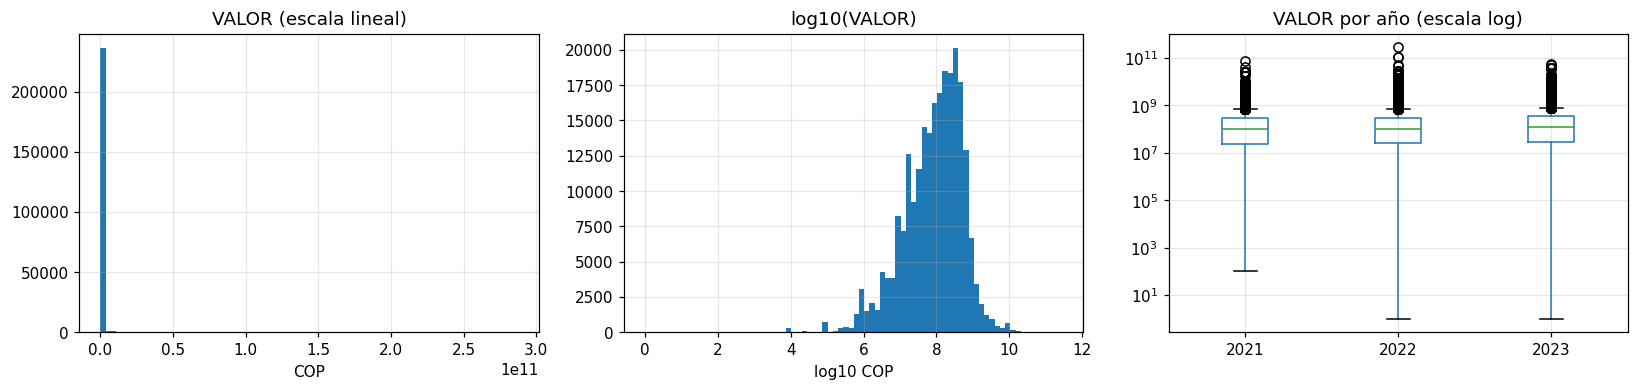

In [93]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(v["VALOR_NUM"], bins=80); ax[0].set_title("VALOR (escala lineal)"); ax[0].set_xlabel("COP")
ax[1].hist(np.log10(v["VALOR_NUM"]), bins=80); ax[1].set_title("log10(VALOR)"); ax[1].set_xlabel("log10 COP")
v.boxplot(column="VALOR_NUM", by="YEAR_RADICA", ax=ax[2], showfliers=True); ax[2].set_yscale("log")
ax[2].set_title("VALOR por año (escala log)"); plt.suptitle(""); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

**Lectura.** La distribución es fuertemente asimétrica (media muy superior a la mediana) y con cola larga; en escala logarítmica se aproxima a una forma más simétrica, lo que orienta una posible transformación futura. Hay valores simbólicos (COP 1, 100, 475) y extremos de decenas de miles de millones: **se conservan**, porque un extremo no implica error y deben revisarse con contexto. La mediana sube entre 2021 y 2023; como se trata de valores nominales y la cobertura de 2021 es menor, **no se debe interpretar esa diferencia como cambio de mercado** sin análisis de sensibilidad.

### 4.6 Cobertura territorial y características del registro

In [94]:
print(df["ORIP"].value_counts().rename("registros").to_frame().assign(**{"%": lambda d: d["registros"]/len(df)*100}).to_string())
print()
print("Folios con más de una fila:", (df.groupby("MATRICULA").size() > 1).sum(), "de", df["MATRICULA"].nunique())
print("Top 5 matrículas por número de filas:")
print(df["MATRICULA"].value_counts().head(5).to_string())

      registros     %
ORIP                 
1       1138519 73.72
01N      405794 26.28

Folios con más de una fila: 387184 de 564314
Top 5 matrículas por número de filas:
MATRICULA
001-131861     84
001-815732     81
01N-335808     69
01N-419837     64
01N-5239864    60


### 4.7 Síntesis de limitaciones

| # | Limitación | Evidencia | Implicación |
|---|---|---|---|
| 1 | **Cobertura monetaria desigual** | 73,76 % en 2021 vs ≈99,5 % en 2022–2023 | Sesgo de cobertura: análisis de sensibilidad por año |
| 2 | **La fila no es una venta independiente** | Escrituras repetidas con el mismo valor | Agrupar por documento; no sumar por fila |
| 3 | **Variables físicas/territoriales ausentes** | Sin área, uso, estrato, coordenadas; catastro vacío | No es un avalúo; alcance de estimación limitado |
| 4 | **Columnas constantes o vacías** | Efecto de filtros y campos sin diligenciar | No aportan información; se descartan para modelar |
| 5 | **Valores extremos y simbólicos** | Mínimos de COP 1 y máximos de decenas de miles de millones | Conservar y revisar; usar métricas robustas |
| 6 | **Fecha ≠ fecha de la operación** | Año de radicación, no de escritura | Ver fecha del documento (parseable) |
| 7 | **Valores nominales** | COP corrientes 2021–2023 | Requiere regla de ajuste si se compara en el tiempo |
| 8 | **Significado de COUNT_A / COUNT_DE / PREDIOS_NUEVOS sin confirmar** | Interpretación provisional | Validar antes de usarlas como predictores |
| 9 | **Representatividad** | Solo actos registrados como compraventa en Medellín urbano | No extrapolar al mercado total |

## 5. Posibles transformaciones
Se construye una **base preparada** con las transformaciones propuestas, sin modificar el original. Cada una queda documentada en la bitácora.

In [95]:
# --- Notarías: normalizar variantes ("NOTARIA 15", "NOTARIA QUINCE", "NOITARIA QUINCE", "DIECICHO"); 0 = notaría única ---
def _construir_ordinales():
    d = {"UNICA":0, "UNICO":0}
    ord10 = ["PRIMER","SEGUND","TERCER","CUART","QUINT","SEXT","SEPTIM","OCTAV","NOVEN","DECIM"]
    for i, r in enumerate(ord10, 1):
        d[r+"A"] = i; d[r+"O"] = i
    sp = {11:"ONCE",12:"DOCE",13:"TRECE",14:"CATORCE",15:"QUINCE",16:"DIECISEIS",17:"DIECISIETE",18:"DIECIOCHO",19:"DIECINUEVE",20:"VEINTE"}
    d.update({v:k for k,v in sp.items()})
    uni = {1:"UN",2:"DOS",3:"TRES",4:"CUATRO",5:"CINCO",6:"SEIS",7:"SIETE",8:"OCHO",9:"NUEVE"}
    for u, w in uni.items():
        for suf in (["O","A"] if u == 1 else [""]):
            d["VEINTI"+w.replace("TRES","TRES")+suf if u > 1 else "VEINTIUN"+suf] = 20+u
    d["VEINTIDOS"], d["VEINTITRES"], d["VEINTISEIS"] = 22, 23, 26
    tens = {30:"TREINTA",40:"CUARENTA",50:"CINCUENTA",60:"SESENTA",70:"SETENTA",80:"OCHENTA",90:"NOVENTA"}
    for t, tw in tens.items():
        d[tw] = t
        for u, w in uni.items():
            for suf in (["O","A"] if u == 1 else [""]):
                d[f"{tw} Y {w}{suf}"] = t+u
    return d
ORD_NUM = _construir_ordinales()
ORD = list(ORD_NUM)

def parse_notaria(txt):
    if not isinstance(txt, str): return (np.nan, np.nan, "sin_dato")
    m = re.match(r"^N\w{3,7}A\s+(.+?)\s+DE(?:L)?\s+(.+)$", txt.strip())
    if not m: return (np.nan, np.nan, "no_parseable")
    ordinal, ciudad = m.group(1).strip(), m.group(2).strip()
    if ordinal.isdigit(): return (int(ordinal), ciudad, "numerica")
    if ordinal in ORD_NUM: return (ORD_NUM[ordinal], ciudad, "exacta")
    cand = difflib.get_close_matches(ordinal, ORD, n=1, cutoff=0.88)   # solo errores tipográficos
    if cand: return (ORD_NUM[cand[0]], ciudad, "typo_corregido")
    return (np.nan, ciudad, "no_resuelta")

res = df["oficina"].map(parse_notaria)
df["NOTARIA_NUM"]   = [r[0] for r in res]
df["NOTARIA_CIUDAD"] = [r[1] for r in res]
df["NOTARIA_METODO"] = [r[2] for r in res]
print(df["NOTARIA_METODO"].value_counts().to_string())
print("\nCiudad de la notaría:"); print(df["NOTARIA_CIUDAD"].value_counts().head(8).to_string())

NOTARIA_METODO
exacta            1203969
no_parseable       328524
numerica             6963
sin_dato             4684
no_resuelta           146
typo_corregido         27

Ciudad de la notaría:
NOTARIA_CIUDAD
MEDELLIN        1154453
ENVIGADO          11601
BOGOTA D. C.      10911
BOGOTA D.C.        6734
ITAGUI             6076
BELLO              2655
LA ESTRELLA        2001
SABANETA           1985


In [96]:
# --- Variables derivadas ---
df["DOC_KEY"]        = df["DOCUMENTO_JUSTIFICATIVO"].str.strip().str.upper()      # llave de agrupación por escritura
df["N_FILAS_DOC"]    = df.groupby("DOC_KEY")["PK"].transform("size")
df["N_MATRICULAS_DOC"] = df.groupby("DOC_KEY")["MATRICULA"].transform("nunique")
df["ANIO_RADICA"]    = df["F_RADICA"].dt.year
df["MES_RADICA_NUM"] = df["F_RADICA"].dt.month
df["DIAS_ESCRITURA_A_RADICACION"] = (df["F_RADICA"] - df["F_DOC"]).dt.days
df["ANTIGUEDAD_FOLIO_ANIOS"] = (df["F_RADICA"] - df["F_APERTURA"]).dt.days / 365.25
df["TIENE_VALOR_POSITIVO"] = (df["VALOR_NUM"] > 0).astype(int)
df["LOG_VALOR"]      = np.log(df["VALOR_NUM"].where(df["VALOR_NUM"] > 0))         # para análisis futuro
# Marcas de calidad (no eliminan filas)
df["FLAG_VALOR_BAJO"]    = ((df["VALOR_NUM"] > 0) & (df["VALOR_NUM"] < 1_000_000)).astype(int)
df["FLAG_VALOR_ALTO"]    = (df["VALOR_NUM"] > 5e9).astype(int)
df["FLAG_FECHA_DOC_INCONSISTENTE"] = ((df["F_DOC"] > df["F_RADICA"]) | (df["DIAS_ESCRITURA_A_RADICACION"] > 365)).astype(int)

# Columnas que no aportan información (constantes o vacías) y variables derivadas del objetivo
descartar = diccionario.loc[diccionario["comportamiento"].isin(["Vacía","Constante"]), "variable"].tolist()
print("Constantes/vacías que se omiten en la base preparada:", descartar)
print("No usar como predictoras (derivan de VALOR):", ["TIENE_VALOR", "TIENE_MAS_DE_UN_VALOR", "TIENE_VALOR_POSITIVO", "LOG_VALOR"])

Constantes/vacías que se omiten en la base preparada: ['DIVIPOLA', 'DEPARTAMENTO', 'MUNICIPIO', 'CATEGORIA_RURALIDAD_2024', ':CREATED_AT', ':UPDATED_AT', 'ESTADO_FOLIO', 'FOLIOS_DERIVADOS']
No usar como predictoras (derivan de VALOR): ['TIENE_VALOR', 'TIENE_MAS_DE_UN_VALOR', 'TIENE_VALOR_POSITIVO', 'LOG_VALOR']


In [97]:
bitacora = pd.DataFrame([
 ("T01","VALOR → VALOR_NUM","Quitar comas de miles y convertir a numérico; conservar VALOR original","Evita errores de lectura; trazable"),
 ("T02","Fechas texto → datetime","FECHA_RADICA, FECHA_APERTURA y fecha dentro del documento","Permite series y antigüedad"),
 ("T03","Parseo de DOCUMENTO_JUSTIFICATIVO","Extraer tipo, número, fecha y oficina con expresión regular","Convierte texto libre en campos"),
 ("T04","Normalización de notarías","Unificar 'NOTARIA 15' / 'QUINCE' y corregir errores tipográficos (difflib, cutoff 0.88)","Reduce categorías espurias"),
 ("T05","DOC_KEY, N_FILAS_DOC, N_MATRICULAS_DOC","Llave de agrupación por escritura","Controla dependencia entre filas y duplicación de montos"),
 ("T06","Variables temporales","Año, mes, días escritura→radicación, antigüedad del folio","Posibles predictores/contexto"),
 ("T07","LOG_VALOR","log(VALOR) solo para VALOR>0","Distribución muy asimétrica; uso futuro"),
 ("T08","Marcas de calidad (FLAG_*)","Señalar valores bajos/altos y fechas inconsistentes sin eliminar","Trazabilidad; revisión contextual"),
 ("T09","Omitir columnas constantes/vacías","Descartar en la base preparada","Sin información"),
 ("T10","Ajuste monetario (NO aplicado)","Deflactar con índice externo solo si se justifica fuente y regla","Valores en COP nominales"),
 ("T11","Imputación de VALOR (NO aplicada)","No imputar; reportar cobertura","Evita inventar el valor objetivo"),
], columns=["id","transformación","descripción","motivo"])
bitacora.to_csv(SALIDAS/"bitacora_transformaciones.csv", index=False, encoding="utf-8-sig")
bitacora

,id,transformación,descripción,motivo
0,T01,VALOR → VALOR_NUM,Quitar comas de miles y convertir a numérico; conservar VALOR original,Evita errores de lectura; trazable
1,T02,Fechas texto → datetime,"FECHA_RADICA, FECHA_APERTURA y fecha dentro del documento",Permite series y antigüedad
2,T03,Parseo de DOCUMENTO_JUSTIFICATIVO,"Extraer tipo, número, fecha y oficina con expresión regular",Convierte texto libre en campos
3,T04,Normalización de notarías,"Unificar 'NOTARIA 15' / 'QUINCE' y corregir errores tipográficos (difflib, c...",Reduce categorías espurias
4,T05,"DOC_KEY, N_FILAS_DOC, N_MATRICULAS_DOC",Llave de agrupación por escritura,Controla dependencia entre filas y duplicación de montos
5,T06,Variables temporales,"Año, mes, días escritura→radicación, antigüedad del folio",Posibles predictores/contexto
6,T07,LOG_VALOR,log(VALOR) solo para VALOR>0,Distribución muy asimétrica; uso futuro
7,T08,Marcas de calidad (FLAG_*),Señalar valores bajos/altos y fechas inconsistentes sin eliminar,Trazabilidad; revisión contextual
8,T09,Omitir columnas constantes/vacías,Descartar en la base preparada,Sin información
9,T10,Ajuste monetario (NO aplicado),Deflactar con índice externo solo si se justifica fuente y regla,Valores en COP nominales


In [98]:
cols_prep = [c for c in df.columns if c not in descartar and c not in ["f_doc","oficina"]]
prep = df[cols_prep].copy()
prep.to_csv(SALIDAS/"base_preparada.csv.gz", index=False, encoding="utf-8-sig", compression="gzip")
print(f"Base preparada: {prep.shape[0]:,} filas x {prep.shape[1]} columnas -> {SALIDAS/'base_preparada.csv.gz'}")
prep.head(3).T

Base preparada: 1,544,313 filas x 42 columnas -> salidas\base_preparada.csv.gz


,0,1,2
PK,05001-001-000013-00014-00313-2018,05001-001-000014-00015-00313-2018,05001-001-000023-00007-00109-2020
MATRICULA,001-13,001-14,001-23
FECHA_RADICA_TEXTO,2018-02-05 00:00:00,2018-02-05 00:00:00,2020-12-02 00:00:00
FECHA_APERTURA_TEXTO,1973-01-11 00:00:00,1973-01-11 00:00:00,1973-01-10 00:00:00
YEAR_RADICA,2018,2018,2020
ORIP,1,1,1
TIPO_PREDIO_ZONA,URBANO,URBANO,URBANO
NUM_ANOTACION,14,15,7
DINAMICA_2024,0,0,1
COD_NATUJUR,313,313,109


## 6. Recursos tecnológicos y necesidades de datos

In [99]:
import importlib
paquetes = ["pandas","numpy","matplotlib","scikit-learn","statsmodels","pyarrow","jupyter"]
vers = {}
for p in paquetes:
    try: vers[p] = importlib.metadata.version(p)
    except Exception: vers[p] = "no instalado"
print("Python:", sys.version.split()[0], "|", platform.platform())
print("Memoria del DataFrame original : %.0f MB" % (raw.memory_usage(deep=True).sum()/1e6))
print("Memoria del DataFrame preparado: %.0f MB" % (prep.memory_usage(deep=True).sum()/1e6))
pd.Series(vers, name="versión").to_frame()

Python: 3.11.9 | Windows-10-10.0.26300-SP0
Memoria del DataFrame original : 829 MB
Memoria del DataFrame preparado: 960 MB


,versión
pandas,3.0.1
numpy,1.26.4
matplotlib,3.10.9
scikit-learn,1.5.2
statsmodels,0.15.0
pyarrow,20.0.0
jupyter,no instalado


### Recursos tecnológicos

| Recurso | Uso | Observación |
|---|---|---|
| **Python + pandas / numpy** | Carga, perfilado, limpieza, transformaciones | Alcanza para 114.590 filas (≈ decenas de MB); no se necesita Spark |
| **Jupyter Notebook** | Diagnóstico reproducible y documentado | Ejecutar de arriba hacia abajo; fija la ruta del CSV |
| **matplotlib** (o seaborn/plotly) | Distribuciones, series y cobertura | |
| **scikit-learn / statsmodels** | *Etapa futura*: referencias estadísticas, regresión, detección de atípicos | No se usan en este notebook |
| **Git (+ DVC opcional)** | Versionar código, bitácora y huella SHA-256 del CSV | El CSV original se guarda protegido y sin pasarlo por Excel |
| **Equipo local** | Todo el trabajo actual | Ver memoria usada arriba; se escalaría a nivel nacional (millones de filas) con Parquet/Spark/DuckDB |
| **Tablero (Power BI / Streamlit)** | *Etapa futura*: Producto Mínimo Viable amigable | Opcional |

**Buenas prácticas.** Abrir el CSV con UTF-8 (Excel puede dañar tildes: `MEDELLÃN`), conservar `dtype=str` al leer, versionar `salidas/` y registrar el hash de cada extracción.

### Necesidades de datos (para la solución futura)

| Necesidad | Por qué | Disponibilidad actual |
|---|---|---|
| Diccionario oficial de variables (COUNT_A, COUNT_DE, PREDIOS_NUEVOS) | Confirmar significado antes de usarlas | **Por obtener** |
| Enlace catastral (área, uso, avalúo, ubicación) | Es la mayor carencia para estimar valor | Campos catastrales vacíos: **por evaluar fuente y llave** |
| Georreferenciación / barrio-comuna | Comparar subterritorios y construir poblaciones comparables | **No disponible** |
| Índice de ajuste monetario (IPC, IPVN, etc.) | Comparar valores nominales 2021–2023 | Externa; **por definir** |
| Mejor cobertura de VALOR en 2021 | 26 % de los registros de 2021 no trae valor | Verificar si es limitación de la fuente |
| Etiquetas de revisión o validación experta | Evaluar utilidad de alertas sin afirmar fraude | **No existen**; requiere evaluador |
| Más años (2015–2020) si se justifica | Series más largas, validación temporal | Disponibles en la fuente nacional |

> **Alcance:** este diagnóstico describe y mide la calidad de los datos. No estima valores ni clasifica operaciones como atípicas, irregulares o fraudulentas.

In [100]:
resumen = {
 "Registros": len(df), "Registros con valor positivo": int((df.VALOR_NUM>0).sum()),
 "Cobertura monetaria (%)": round((df.VALOR_NUM>0).mean()*100, 2),
 "Documentos distintos": df["DOC_KEY"].nunique(),
 "Columnas totales / con información": f"{raw.shape[1]} / {(diccionario.comportamiento=='Variable').sum()}",
 "Reglas de calidad evaluadas": len(reglas),
}
pd.Series(resumen, name="resumen").to_frame()

,resumen
Registros,1544313
Registros con valor positivo,237985
Cobertura monetaria (%),15.41
Documentos distintos,442376
Columnas totales / con información,27 / 19
Reglas de calidad evaluadas,15
